# AICS-202 | Laboratory 04
## Defensive Retraining and Robustness Assessment
Course module: 4 | Suggested duration: 5 hours

**Objective:** compare a baseline model with a model trained using simple augmented adversarial samples. Independently evaluate both models with FGSM and a small PGD variant.

**Important:** augmentation is not a guarantee of robustness; attacks must be adapted to the defended model to avoid misleading results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


In [2]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

In [3]:
def pgd(model, features, labels, epsilon=0.12, alpha=0.03, steps=7, seed=42):
    rng = np.random.default_rng(seed)
    original = features.copy()
    perturbed = np.clip(original + rng.uniform(-epsilon, epsilon, size=original.shape), 0, 1)
    for _ in range(steps):
        grad = input_loss_gradient(model, perturbed, labels)
        perturbed = perturbed + alpha * np.sign(grad)
        perturbed = np.maximum(np.minimum(perturbed, original + epsilon), original - epsilon)
        perturbed = np.clip(perturbed, 0.0, 1.0)
    return perturbed

Baseline: clean=0.962 | FGSM=0.516 | PGD=0.489
Augmented training (aug eps 0.10): clean=0.940 | FGSM=0.284 | PGD=0.260
Variant (aug eps 0.03): clean=0.962 | FGSM=0.467 | PGD=0.438

Model | Clean | FGSM | PGD | change vs baseline in percentage points (clean/FGSM/PGD)
Baseline | 0.962 | 0.516 | 0.489 | +0.0 / +0.0 / +0.0
Augmented (aug eps 0.10) | 0.940 | 0.284 | 0.260 | -2.2 / -23.1 / -22.9
Variant (aug eps 0.03) | 0.962 | 0.467 | 0.438 | +0.0 / -4.9 / -5.1


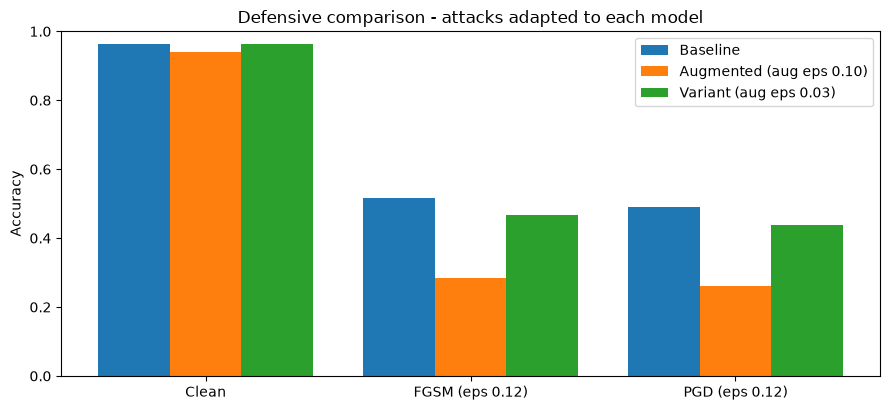

In [4]:
# Three models. Every attack is generated AGAINST THE MODEL BEING TESTED (adaptive white-box).
# Student variant: augmentation epsilon 0.03 (weaker than the supplied 0.10) to test whether a smaller shift hurts less.
import csv, os
os.makedirs('results', exist_ok=True)
def make_defended(aug_eps):
    adv = fgsm(model, X_train, y_train, epsilon=aug_eps)      # crafted against the baseline, as in the supplied lab
    return build_model(np.concatenate([X_train, adv]), np.concatenate([y_train, y_train]))
defended = make_defended(0.10)
variant = make_defended(0.03)

def evaluate(model_to_test, label):
    clean = accuracy_score(y_test, model_to_test.predict(X_test))
    test_fgsm = fgsm(model_to_test, X_test, y_test, epsilon=0.12)
    test_pgd = pgd(model_to_test, X_test, y_test, epsilon=0.12, alpha=0.03, steps=7)
    fgsm_acc = accuracy_score(y_test, model_to_test.predict(test_fgsm))
    pgd_acc = accuracy_score(y_test, model_to_test.predict(test_pgd))
    print(f'{label}: clean={clean:.3f} | FGSM={fgsm_acc:.3f} | PGD={pgd_acc:.3f}')
    return [clean, fgsm_acc, pgd_acc]
base_results = evaluate(model, 'Baseline')
def_results = evaluate(defended, 'Augmented training (aug eps 0.10)')
var_results = evaluate(variant, 'Variant (aug eps 0.03)')

names = ['Baseline', 'Augmented (aug eps 0.10)', 'Variant (aug eps 0.03)']
allres = [base_results, def_results, var_results]
print('\nModel | Clean | FGSM | PGD | change vs baseline in percentage points (clean/FGSM/PGD)')
with open('results/E06_defence_results.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['model', 'clean', 'fgsm_eps0.12', 'pgd_eps0.12', 'd_clean_pp', 'd_fgsm_pp', 'd_pgd_pp'])
    for nm, r in zip(names, allres):
        d = [round(100*(r[i]-base_results[i]), 1) for i in range(3)]
        w.writerow([nm] + [round(v, 4) for v in r] + d)
        print(f'{nm} | {r[0]:.3f} | {r[1]:.3f} | {r[2]:.3f} | {d[0]:+.1f} / {d[1]:+.1f} / {d[2]:+.1f}')
ind = np.arange(3)
fig, ax = plt.subplots(figsize=(9,4.2))
for k, (nm, r) in enumerate(zip(names, allres)):
    ax.bar(ind + (k-1)*.27, r, width=.27, label=nm)
ax.set_xticks(ind, ['Clean', 'FGSM (eps 0.12)', 'PGD (eps 0.12)']); ax.set_ylim(0,1)
ax.set_ylabel('Accuracy'); ax.set_title('Defensive comparison - attacks adapted to each model')
ax.legend(); plt.tight_layout(); plt.savefig('results/E06_defence_comparison.png', dpi=200, bbox_inches='tight'); plt.show()

In [5]:
# ADDED CELL (diagnostics for the written explanation; these are evidence for hypotheses, not proof)
# 1) Static vs adaptive: attack crafted against the BASELINE, applied to the defended model.
static_adv = fgsm(model, X_test, y_test, epsilon=0.12)
print('Defended model on attack crafted against BASELINE (non-adaptive):', round(accuracy_score(y_test, defended.predict(static_adv)), 3))
print('Defended model on attack crafted against ITSELF (adaptive)      :', round(def_results[1], 3))
# 2) Weight size: for a linear model, FGSM effect grows with the size of the weights.
for nm, m in [('Baseline', model), ('Augmented 0.10', defended), ('Variant 0.03', variant)]:
    print(f'{nm}: mean |weight| = {np.abs(m.coef_).mean():.3f} | L2 norm of weights = {np.linalg.norm(m.coef_):.2f}')
# 3) Is the ordering stable? 5 different train/test splits (baseline vs aug 0.10 vs aug 0.03), adaptive FGSM eps 0.12.
print('split | baseline | aug 0.10 | aug 0.03   (FGSM accuracy)')
for s in [1, 7, 13, 42, 99]:
    a, b, c, d = train_test_split(X, y, test_size=0.25, random_state=s, stratify=y)
    mk = lambda f_, l_: LogisticRegression(max_iter=600, random_state=s).fit(f_, l_)
    b0 = mk(a, c); row = [accuracy_score(d, b0.predict(fgsm(b0, b, d, 0.12)))]
    for ae in [0.10, 0.03]:
        m2 = mk(np.concatenate([a, fgsm(b0, a, c, ae)]), np.concatenate([c, c]))
        row.append(accuracy_score(d, m2.predict(fgsm(m2, b, d, 0.12))))
    print(f'{s:5d} | {row[0]:.3f} | {row[1]:.3f} | {row[2]:.3f}')

Defended model on attack crafted against BASELINE (non-adaptive): 0.86
Defended model on attack crafted against ITSELF (adaptive)      : 0.284
Baseline: mean |weight| = 0.448 | L2 norm of weights = 17.01
Augmented 0.10: mean |weight| = 0.695 | L2 norm of weights = 24.09
Variant 0.03: mean |weight| = 0.573 | L2 norm of weights = 21.43
split | baseline | aug 0.10 | aug 0.03   (FGSM accuracy)
    1 | 0.502 | 0.284 | 0.451
    7 | 0.498 | 0.289 | 0.462
   13 | 0.504 | 0.269 | 0.491
   42 | 0.516 | 0.284 | 0.467
   99 | 0.524 | 0.302 | 0.502


### Final practical evidence and risk conclusion
1. Compare clean-test and attacked-test accuracy for both models.
2. Explain why defensive effectiveness must be tested against the defended model itself.
3. Identify three limitations of this small dataset and short attack budget.
4. Produce a one-page robustness decision memo: deploy, improve or reject, with a rationale.

**Deliverables:** comparison chart, numeric results, limitations and decision memo. This is a local learning exercise, not a certification of model security.